# 02 - Exploratory Data Analysis (EDA)

Author: Ahmed Shahzad

**Goal:** understand the cleaned data with charts and numbers *before* modelling: what the target looks like, which features separate the classes, and whether features overlap with each other.

All charts are also saved to `reports/figures/` so they can be reused in the README or a presentation.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 90

FIG = Path("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

RISK_ORDER = ["low risk", "mid risk", "high risk"]
RISK_COLORS = {"low risk": "#12B886", "mid risk": "#F5A524", "high risk": "#FF4D6D"}

mat = pd.read_csv("data/processed/maternal_clean.csv")
mat["RiskLevel"] = pd.Categorical(mat["RiskLevel"], categories=RISK_ORDER, ordered=True)
pul = pd.read_csv("data/processed/pulsar_clean.csv")
print("Maternal:", mat.shape, "| Pulsar:", pul.shape)

Maternal: (451, 7) | Pulsar: (17898, 9)


# Part A - Maternal Health Risk

### A1. How many women in each risk level?

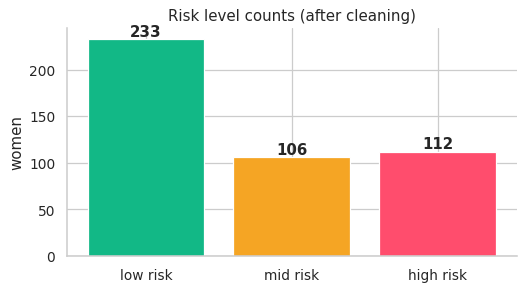

RiskLevel
low risk     0.517
mid risk     0.235
high risk    0.248


In [2]:
counts = mat["RiskLevel"].value_counts().reindex(RISK_ORDER)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(counts.index, counts.values, color=[RISK_COLORS[c] for c in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v + 3, str(v), ha="center", fontweight="bold")
ax.set_ylabel("women")
ax.set_title("Risk level counts (after cleaning)")
sns.despine()
fig.tight_layout()
fig.savefig(FIG / "maternal_class_counts.png", dpi=150)
plt.show()
print((counts / counts.sum()).round(3).to_string())

Low risk is the biggest group, but all three classes have a reasonable number of examples (no extreme imbalance). We will still keep the class split the same in train and test using stratified splitting.

### A2. Do the vitals differ between risk levels?

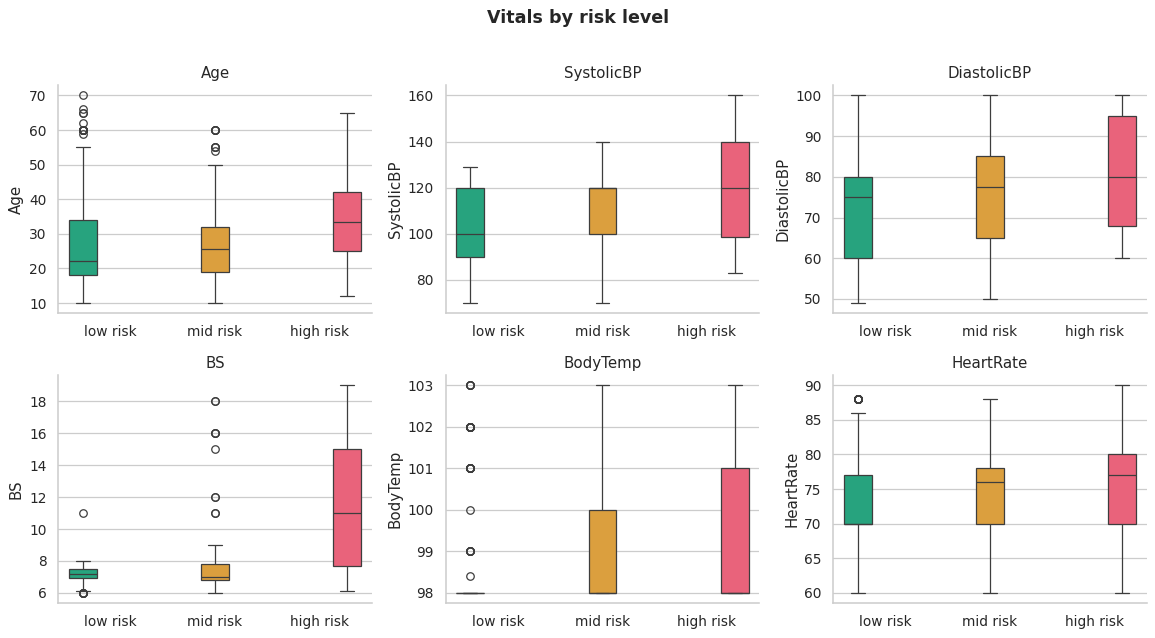

In [3]:
features = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=mat, x="RiskLevel", y=col, order=RISK_ORDER, palette=RISK_COLORS, ax=ax, hue="RiskLevel", legend=False)
    ax.set_xlabel("")
    ax.set_title(col)
sns.despine()
fig.suptitle("Vitals by risk level", y=1.01, fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "maternal_vitals_by_risk.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
display(mat.groupby("RiskLevel", observed=True)[features].median().round(1))

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
RiskLevel,,,,,,
low risk,22.0,100.0,75.0,7.2,98.0,70.0
mid risk,25.5,120.0,77.5,7.0,98.0,76.0
high risk,33.5,120.0,80.0,11.0,98.0,77.0


Blood sugar (`BS`) and the blood pressure values are higher for mid and high risk than for low risk, and the typical age rises from low to high risk. `BodyTemp` has the same median (98 F) in every group, but the few fever readings above 98 F appear mostly in mid and high risk. `HeartRate` changes very little between groups. Mid risk sits between the other two on most vitals, so we expect it to be the hardest class to separate.

### A3. Which vitals move together?

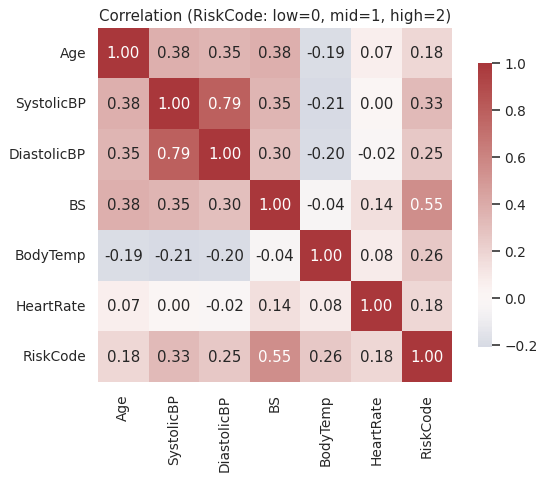

BS             0.55
SystolicBP     0.33
BodyTemp       0.26
DiastolicBP    0.25
HeartRate      0.18
Age            0.18


In [5]:
enc = mat.copy()
enc["RiskCode"] = enc["RiskLevel"].cat.codes   # low=0, mid=1, high=2
corr = enc[features + ["RiskCode"]].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlation (RiskCode: low=0, mid=1, high=2)")
fig.tight_layout()
fig.savefig(FIG / "maternal_correlation.png", dpi=150)
plt.show()
print(corr["RiskCode"].drop("RiskCode").sort_values(ascending=False).round(2).to_string())

`BS` has the strongest link with risk (about 0.55), then `SystolicBP` (about 0.33). `BodyTemp` and `DiastolicBP` are close to 0.25, and `HeartRate` and `Age` are weakest in a straight-line sense (about 0.18), although the boxplots show age still differs by group. Systolic and diastolic pressure are strongly correlated with each other (they are measured together), so a linear model would see some overlap between them, while tree-based models cope with that easily.

### A4. Two strong signals together

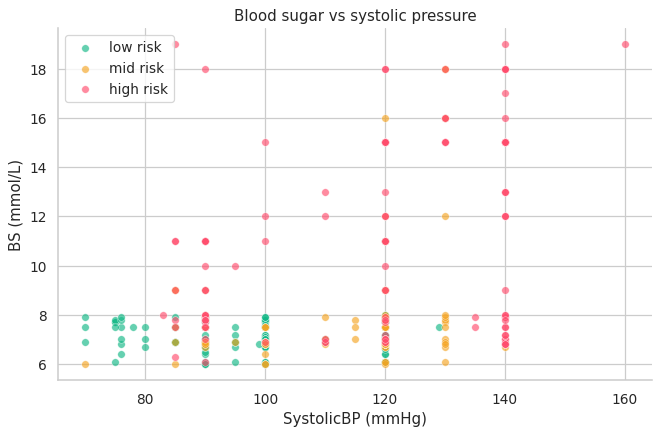

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for risk in RISK_ORDER:
    sub = mat[mat["RiskLevel"] == risk]
    ax.scatter(sub["SystolicBP"], sub["BS"], s=36, alpha=.65, color=RISK_COLORS[risk], label=risk, edgecolor="white", linewidth=.4)
ax.set_xlabel("SystolicBP (mmHg)")
ax.set_ylabel("BS (mmol/L)")
ax.set_title("Blood sugar vs systolic pressure")
ax.legend(title="")
sns.despine()
fig.tight_layout()
fig.savefig(FIG / "maternal_bs_vs_bp.png", dpi=150)
plt.show()

High-risk women gather toward high blood sugar and high pressure, but the colours overlap in the middle. That overlap is the same ceiling we saw in notebook 01 (identical vitals with different labels), so we should not expect near-perfect accuracy.

### Maternal - key findings

1. 451 women after cleaning: 233 low, 106 mid, 112 high risk.
2. `BS` and `SystolicBP` separate the classes best; `HeartRate` is the weakest signal.
3. Mid risk overlaps with both neighbours, so it will be the hardest class.
4. Tree-based models are a good fit: they handle overlapping, non-linear patterns without scaling.

# Part B - HTRU2 Pulsar Candidates

### B1. The target: how rare are pulsars?

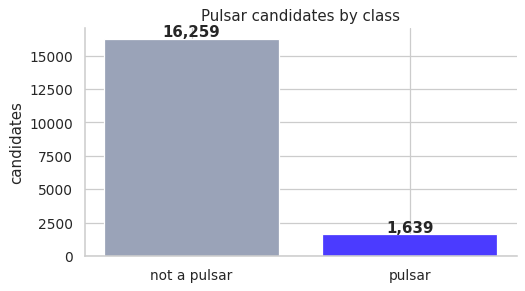

Pulsar share: 9.16%


In [7]:
counts = pul["is_pulsar"].value_counts().sort_index()
labels = ["not a pulsar", "pulsar"]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, counts.values, color=["#9AA3B8", "#4B3BFF"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 150, f"{v:,}", ha="center", fontweight="bold")
ax.set_ylabel("candidates")
ax.set_title("Pulsar candidates by class")
sns.despine()
fig.tight_layout()
fig.savefig(FIG / "pulsar_class_counts.png", dpi=150)
plt.show()
print(f"Pulsar share: {counts[1] / counts.sum():.2%}")

Only about 1 candidate in 11 is a real pulsar. Accuracy would be misleading here, so we will use precision (how many flagged candidates are real), recall (how many real pulsars we catch), F1 and PR-AUC.

### B2. How do the two classes differ on each feature?

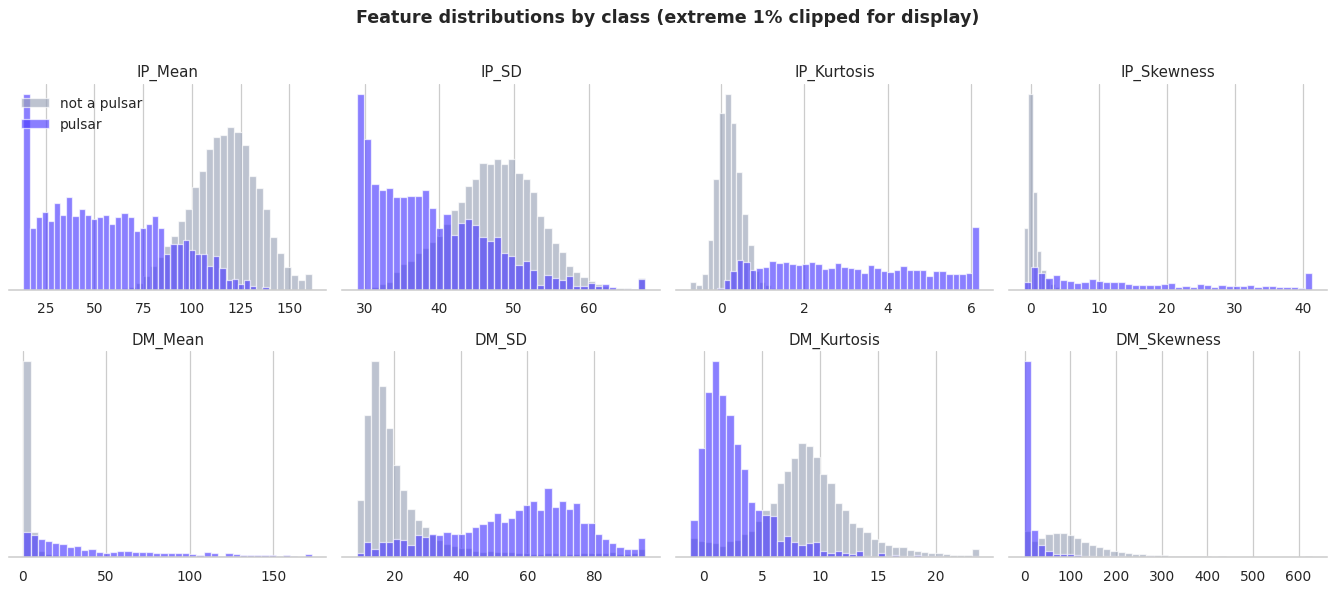

In [8]:
pcols = [c for c in pul.columns if c != "is_pulsar"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.ravel(), pcols):
    lo, hi = pul[col].quantile([.005, .995])
    for cls, color, name in [(0, "#9AA3B8", "not a pulsar"), (1, "#4B3BFF", "pulsar")]:
        vals = pul.loc[pul["is_pulsar"] == cls, col].clip(lo, hi)
        ax.hist(vals, bins=40, density=True, alpha=.65, color=color, label=name)
    ax.set_title(col)
    ax.set_yticks([])
axes[0, 0].legend(frameon=False)
sns.despine(left=True)
fig.suptitle("Feature distributions by class (extreme 1% clipped for display)", y=1.01, fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "pulsar_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

Pulsars have a much higher kurtosis and skewness in the integrated profile (`IP_Kurtosis`, `IP_Skewness`): a real pulsar gives one sharp, narrow pulse, while noise gives a flat, shapeless profile. On the DM-SNR curve, pulsars show higher mean, spread and a clearly different shape. The two classes are well separated on several features at once.

### B3. Which single feature separates the classes best?

In [9]:
auc = {c: roc_auc_score(pul["is_pulsar"], pul[c]) for c in pcols}
sep = pd.Series({c: max(a, 1 - a) for c, a in auc.items()}).sort_values(ascending=False)
direction = pd.Series({c: "higher in pulsars" if auc[c] >= .5 else "lower in pulsars" for c in pcols})

table = pd.DataFrame({"single-feature ROC-AUC": sep.round(3), "direction": direction[sep.index]})
display(table)

,single-feature ROC-AUC,direction
IP_Kurtosis,0.972,higher in pulsars
IP_Mean,0.951,lower in pulsars
IP_Skewness,0.941,higher in pulsars
DM_SD,0.895,higher in pulsars
DM_Mean,0.893,higher in pulsars
DM_Skewness,0.887,lower in pulsars
DM_Kurtosis,0.885,lower in pulsars
IP_SD,0.813,lower in pulsars


A single feature is already strong on its own, and `IP_Kurtosis` leads the list. Combining all 8 should do even better. Note that `IP_Mean` is the one feature that goes the other way: pulsars have a *lower* integrated-profile mean than noise.

### B4. Do features overlap?

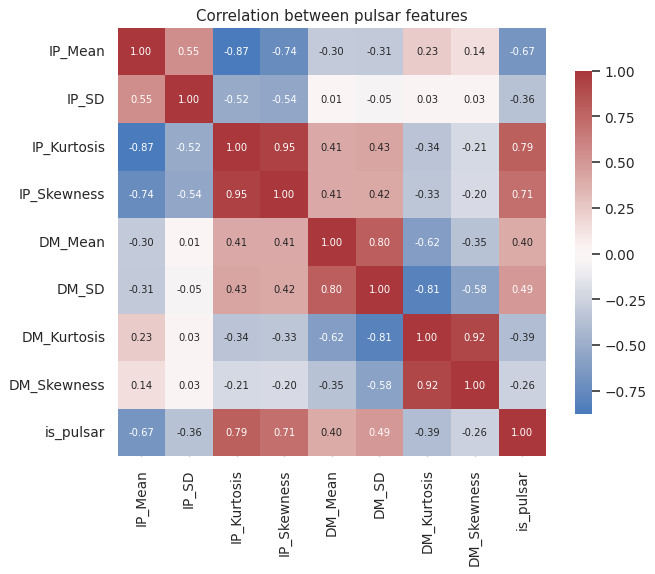

In [10]:
corr = pul[pcols + ["is_pulsar"]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, cbar_kws={"shrink": .8}, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation between pulsar features")
fig.tight_layout()
fig.savefig(FIG / "pulsar_correlation.png", dpi=150)
plt.show()

Several features are strongly correlated (for example `IP_Kurtosis` with `IP_Skewness`, and the DM-SNR kurtosis with its skewness). They are different views of the same shape, so they carry overlapping information. That is fine for tree-based models and for prediction, but it means individual coefficients of a linear model would be harder to interpret.

### Pulsar - key findings

1. 17,898 candidates, only 9.16% pulsars: judge with precision / recall / F1 / PR-AUC, never accuracy alone.
2. The shape statistics of the integrated profile (kurtosis, skewness) are the strongest single signals.
3. Features overlap, and several are heavy-tailed; tree ensembles are a natural fit.
4. Because the classes are imbalanced, we will also tune the **decision threshold**, not just the model.

## What we carry into modelling (notebook 03)

| Decision | Maternal | Pulsar |
|---|---|---|
| Target | `RiskLevel` (3 classes, ordered) | `is_pulsar` (binary) |
| Features | 6 vitals | 8 profile / DM-SNR statistics |
| Split | 80/20, stratified, after removing duplicates | 80/20, stratified |
| Candidates | Logistic Regression, Random Forest, Gradient Boosting | Logistic Regression, Random Forest, Hist. Gradient Boosting |
| Selection metric | cross-validated macro F1 | cross-validated PR-AUC (average precision) |
| Extra | report high-risk recall | tune the decision threshold on out-of-fold predictions |